In [3]:
# import packages
import pandas as pd
import requests
import os
from dotenv import load_dotenv
import matplotlib
from matplotlib import pylab as plt
import seaborn as sns

In [4]:
# construct the API request
request_params = {
    'api_key': os.getenv('API_KEY'),
    'limit': 4000
}

api_url = 'https://developer.nps.gov/api/v1/thingstodo'
response = requests.get(api_url, params = request_params)

# check the API response
if response.status_code == 200:
    todo_data = response.json()
else:
    print(f'Response Code: {response.status_code}')
    print(f'Error Message: {response.text}')
    raise ValueError('Unsuccessful Request')


In [5]:
# save the data
selected_columns = [
    'doFeesApply',
    'isReservationRequired',
    'arePetsPermitted', 
    'tags', 
    'topics',   
    'timeOfDay',  
    'season',  
    'relatedParks',  
]

raw_todo_df = pd.DataFrame(todo_data['data'])
raw_todo_df.to_csv('../data/raw_todo.csv', index = False)
selected_todo_df = raw_todo_df[selected_columns].copy()
selected_todo_df.to_csv('../data/selected_todo.csv', index = False)


In [6]:
# count missing values for each column
for col in selected_todo_df.columns:
    if selected_todo_df[col].dtype == 'object':
        missing_count = sum(selected_todo_df[col].astype(str) == '[]')
        print(f"{col}: {missing_count} missing values")
    else:
        missing_count = sum(selected_todo_df[col] == '')
        print(f"{col}: {missing_count} missing values")

doFeesApply: 0 missing values
isReservationRequired: 0 missing values
arePetsPermitted: 0 missing values
tags: 338 missing values
topics: 0 missing values
timeOfDay: 801 missing values
season: 540 missing values
relatedParks: 112 missing values


In [7]:
eda_todo_df = selected_todo_df.copy()

# convert tags and topics to their lengths
for col in ['tags', 'topics']:
    eda_todo_df[col] = eda_todo_df[col].apply(lambda x: len(x) if isinstance(x, list) else 0)



In [8]:
# extract states from relatedParks and map to regions
region_map = {
    # Northeast 
    'CT': 'Northeast', 'ME': 'Northeast', 'MA': 'Northeast', 'NH': 'Northeast', 
    'RI': 'Northeast', 'VT': 'Northeast', 'NJ': 'Northeast', 'NY': 'Northeast', 'PA': 'Northeast',
    
    # Midwest 
    'IL': 'Midwest', 'IN': 'Midwest', 'MI': 'Midwest', 'OH': 'Midwest', 'WI': 'Midwest',
    'IA': 'Midwest', 'KS': 'Midwest', 'MN': 'Midwest', 'MO': 'Midwest', 'NE': 'Midwest', 
    'ND': 'Midwest', 'SD': 'Midwest',
    
    # South 
    'DE': 'South', 'DC': 'South', 'FL': 'South', 'GA': 'South', 'MD': 'South', 
    'NC': 'South', 'SC': 'South', 'VA': 'South', 'WV': 'South', 'AL': 'South', 
    'KY': 'South', 'MS': 'South', 'TN': 'South', 'AR': 'South', 'LA': 'South', 
    'OK': 'South', 'TX': 'South',
    
    # West 
    'AZ': 'West', 'CO': 'West', 'ID': 'West', 'MT': 'West', 'NV': 'West', 
    'NM': 'West', 'UT': 'West', 'WY': 'West', 'AK': 'West', 'CA': 'West', 
    'HI': 'West', 'OR': 'West', 'WA': 'West',

    # Territories 
    'PR': 'Territories', 
    'VI': 'Territories', 
    'GU': 'Territories', 
    'AS': 'Territories', 
    'MP': 'Territories'  
}

eda_todo_df['regions'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        region_map[state.strip()]
        for park in (val or [])       
        for state in str(park.get('states', '')).split(',')
    })
)


In [9]:
# extract designations from relatedParks and categorize parks
eda_todo_df['designations'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        park.get('designation')
        for park in (val or [])
        if park.get('designation')  
    })
)

def categorize_park(name):
    name = str(name).strip()

    if name in [
        'National Park', 'National Parks',
        'National and State Parks', 'National Park & Preserve'
    ]:
        return "National_Park"
    
    elif any(x in name for x in [
        'Historical', 'Historic', 'International Historic'
    ]):
        return "Historical_Site"
    
    elif any(x in name for x in [
        'Monument', 'Memorial', 'Battlefield', 'Military Park'
    ]):
        return "National_Monument"
    
    elif any(x in name for x in [
        'Recreation', 'Parkway', 'Lakeshore', 'Seashore'
    ]):
        return 'Recreation_Area'
    
    else:
        return 'Other_Protected_Area'


eda_todo_df['park_categories'] = eda_todo_df['designations'].apply(
    lambda des_list: sorted({
        categorize_park(des)        
        for des in (des_list or [])
    })
)



In [10]:
# drop the original columns and save the EDA dataframe to a CSV file
eda_todo_df = eda_todo_df.drop(columns = ['relatedParks', 'designations'])
eda_todo_df.to_csv('../data/eda_todo.csv', index = False)

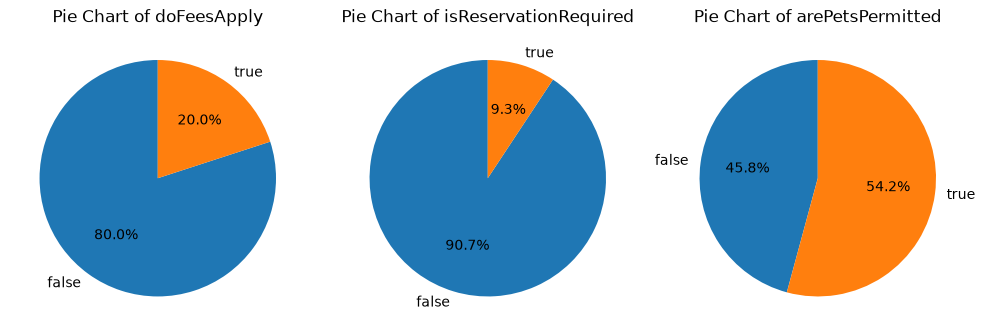

In [ ]:
# create pie charts for doFeesApply, isReservationRequired, and arePetsPermitted
pie_cols = ['doFeesApply', 'isReservationRequired', 'arePetsPermitted']

fig, axes = plt.subplots(1, 3, figsize = (10, 6))
for ax, col in zip(axes, pie_cols):
   counts = eda_todo_df[col].value_counts().sort_index()
   ax.pie(counts, labels = counts.index, autopct = '%1.1f%%', startangle = 90)
   ax.set_title(f'Pie Chart of {col}')
plt.tight_layout()
plt.show()